# Piekdetectie en spectra-matching, stap voor stap

**User story (LS):** *"Als ontwikkelaar wil ik leren hoe een algoritme voor piekdetectie en spectra-matching werkt,
zodat ik de theorie begrijp die nodig is om de database-vergelijking te programmeren."*

Dit notebook laat zien **hoe de IR-Stofherkenner pieken vindt en spectra vergelijkt**. Het gebruikt dezelfde code als de
app (de map `stofherkenner/`), maar voert de stappen één voor één uit en tekent wat er gebeurt.

| Deel | Wat | Waarom |
|---|---|---|
| A | Een **zelfgemaakt** spectrum met pieken op bekende plekken, plus ruis | We weten het goede antwoord, dus we kunnen controleren of *precies* de juiste pieken gevonden worden |
| B | Een **echt** spectrum uit de NIST-database: aceton | Werkt het ook op echte data? De C=O-piek van aceton hoort rond 1700–1750 cm⁻¹ te liggen |
| C | **Matching**: twee spectra vergelijken met een getal | De basis van de zoekactie in de bibliotheek |

Er wordt nergens een model getraind. Alles is een vaste rekenregel die je kunt narekenen.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks, savgol_filter

# De projectmap toevoegen, zodat we de code van de app kunnen gebruiken
PROJECTMAP = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECTMAP))

from stofherkenner.jcamp_lezen import lees_jcamp_bestand
from stofherkenner.piekdetectie import detecteer_pieken, maak_glad, schat_ruis
from stofherkenner.voorbewerking import RASTER, bewerk_voor, vergelijkingsvorm

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})

def ir_as(ax, titel=""):
    # IR-conventie: golfgetal van hoog (links) naar laag (rechts)
    ax.invert_xaxis()
    ax.set_xlabel("Golfgetal (cm⁻¹)")
    ax.set_title(titel)

print("Python:", sys.executable)
print(f"Raster van de app: {RASTER[0]:.0f} t/m {RASTER[-1]:.0f} cm⁻¹ in stappen van {RASTER[1]-RASTER[0]:.0f} cm⁻¹ ({len(RASTER)} punten)")

Python: C:\claude code\ir-stofherkenner\.venv\Scripts\python.exe
Raster van de app: 550 t/m 3798 cm⁻¹ in stappen van 4 cm⁻¹ (813 punten)


---
## Deel A – Een zelfgemaakt spectrum met bekende pieken

We maken zelf een spectrum met **vijf pieken waarvan we de positie precies weten**. Elke piek is een klokvorm
(Gauss-curve). Daar tellen we willekeurige **ruis** bij op, zoals een echte meting die ook heeft. Als de piekdetectie
goed werkt, vindt hij straks precies deze vijf pieken en geen enkele "nep-piek" uit de ruis.

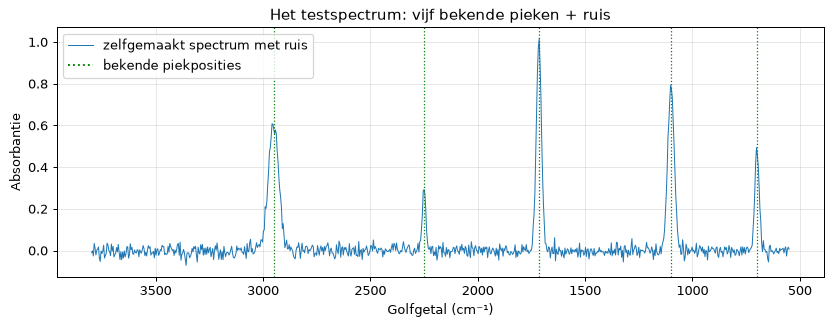

In [2]:
def gauss(x, midden, hoogte, breedte):
    # Klokvormige piek: 'midden' = positie, 'hoogte' = top, 'breedte' = hoe breed (sigma)
    return hoogte * np.exp(-0.5 * ((x - midden) / breedte) ** 2)

# De "waarheid": positie (cm⁻¹), hoogte, breedte
BEKENDE_PIEKEN = [(700, 0.50, 10), (1100, 0.80, 15), (1715, 1.00, 12), (2250, 0.30, 8), (2950, 0.60, 25)]
RUIS = 0.02                                     # standaarddeviatie van de ruis (2% van de hoogste piek)

rng = np.random.default_rng(seed=1)             # vaste 'seed': elke keer dezelfde ruis, dus reproduceerbaar
x = RASTER
schoon = sum(gauss(x, p, h, b) for p, h, b in BEKENDE_PIEKEN)
ruw = schoon + rng.normal(0.0, RUIS, x.size)    # het "gemeten" spectrum

fig, ax = plt.subplots()
ax.plot(x, ruw, lw=0.8, label="zelfgemaakt spectrum met ruis")
for p, h, b in BEKENDE_PIEKEN:
    ax.axvline(p, color="green", ls=":", lw=1)
ax.plot([], [], color="green", ls=":", label="bekende piekposities")
ax.set_ylabel("Absorbantie"); ax.legend(); ir_as(ax, "Het testspectrum: vijf bekende pieken + ruis")
plt.show()

### Het probleem: ruis heeft ook "pieken"

De simpelste definitie van een piek is: *een punt dat hoger is dan zijn twee buren* (een lokaal maximum).
Laten we kijken hoeveel van zulke punten er in het ruwe spectrum zitten.

Lokale maxima in het ruwe spectrum: 249   (echte pieken: 5)


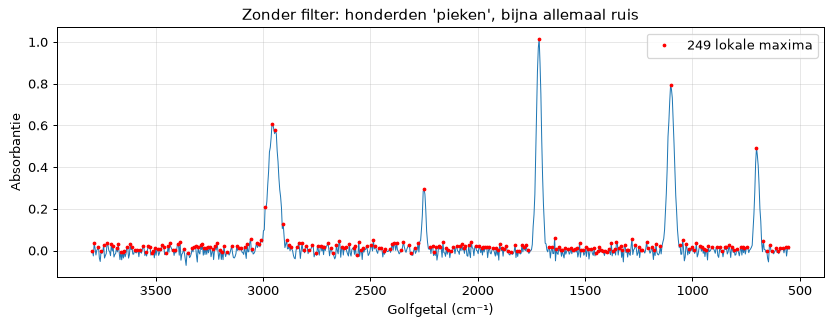

In [3]:
alle_maxima, _ = find_peaks(ruw)                # zonder enige eis: elk lokaal maximum telt
print(f"Lokale maxima in het ruwe spectrum: {len(alle_maxima)}   (echte pieken: {len(BEKENDE_PIEKEN)})")

fig, ax = plt.subplots()
ax.plot(x, ruw, lw=0.8)
ax.plot(x[alle_maxima], ruw[alle_maxima], "r.", ms=4, label=f"{len(alle_maxima)} lokale maxima")
ax.set_ylabel("Absorbantie"); ax.legend(); ir_as(ax, "Zonder filter: honderden 'pieken', bijna allemaal ruis")
plt.show()

Dat is onbruikbaar. We hebben vier stappen nodig om echte pieken van ruis te onderscheiden.

### Stap 1 – Gladmaken met een Savitzky-Golay-filter

Het filter schuift een **venster** van een paar punten (hier 7) over het spectrum. Door die 7 punten legt het telkens
een vloeiend **boogje** (een derdegraads polynoom) en neemt de waarde van dat boogje in het midden.

Waarom niet gewoon het gemiddelde van 7 punten nemen? Een gemiddelde maakt een piek **lager en breder**. Een boogje
kan de kromming van een piek volgen, waardoor hoogte en breedte veel beter behouden blijven.

Hoogte van de piek bij 2250: echt 0.300 | Savitzky-Golay 0.290 | gewoon gemiddelde 0.201
Aantal lokale maxima na gladmaken: 173 (was 249)


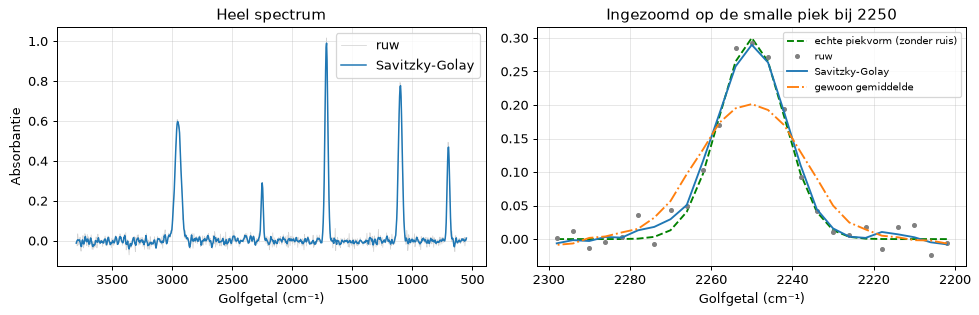

In [4]:
glad = savgol_filter(ruw, window_length=7, polyorder=3)      # dit is wat maak_glad() in de app doet
gemiddelde = np.convolve(ruw, np.ones(7) / 7, mode="same")   # ter vergelijking: gewoon voortschrijdend gemiddelde

fig, (links, rechts) = plt.subplots(1, 2, figsize=(11, 3.6))
links.plot(x, ruw, lw=0.6, color="lightgray", label="ruw")
links.plot(x, glad, lw=1.2, label="Savitzky-Golay")
links.set_ylabel("Absorbantie"); links.legend(); ir_as(links, "Heel spectrum")

zoom = (x > 2200) & (x < 2300)                                # de smalste piek (bij 2250)
rechts.plot(x[zoom], schoon[zoom], "g--", label="echte piekvorm (zonder ruis)")
rechts.plot(x[zoom], ruw[zoom], ".", color="gray", label="ruw")
rechts.plot(x[zoom], glad[zoom], lw=1.5, label="Savitzky-Golay")
rechts.plot(x[zoom], gemiddelde[zoom], lw=1.5, ls="-.", label="gewoon gemiddelde")
rechts.legend(fontsize=8); ir_as(rechts, "Ingezoomd op de smalle piek bij 2250")
plt.tight_layout(); plt.show()

echte_top = schoon[zoom].max()
print(f"Hoogte van de piek bij 2250: echt {echte_top:.3f} | Savitzky-Golay {glad[zoom].max():.3f} | gewoon gemiddelde {gemiddelde[zoom].max():.3f}")
print(f"Aantal lokale maxima na gladmaken: {len(find_peaks(glad)[0])} (was {len(alle_maxima)})")

Het gladmaken helpt, maar er blijven nog veel kleine bobbeltjes over. We moeten dus weten **hoe groot de ruis is**.

### Stap 2 – Het ruisniveau schatten met de MAD

Idee: trek het gladde spectrum af van het ruwe spectrum. Wat overblijft (het **restant**) is vooral ruis.

Hoe groot is die ruis? De gewone standaarddeviatie is hier onbetrouwbaar: op de plek van een piek volgt het filter de
top niet perfect, wat een paar grote uitschieters in het restant geeft. Die trekken de standaarddeviatie omhoog.

Daarom gebruiken we de **MAD** (*median absolute deviation*):

1. neem van elk punt de absolute afwijking van de mediaan;
2. neem daarvan weer de **mediaan**.

Een mediaan trekt zich niets aan van een paar uitschieters. Voor gewone (normaal verdeelde) ruis geldt:
**standaarddeviatie ≈ 1,4826 × MAD**.

Ruis die we er zelf in stopten      : 0.0200
Geschat met MAD (restant)           : 0.0166   <- de app gebruikt deze
Zelfde uitkomst met de app-functie  : 0.0166
Gewone standaarddeviatie HEEL spectrum: 0.1321   <- veel te groot: de pieken tellen mee

Let op: de schatting is 17% lager dan de echte ruis, omdat het filter een deel
van de ruis 'volgt' en dat deel niet in het restant belandt. Daarom gebruiken we straks een ruime factor (5x).


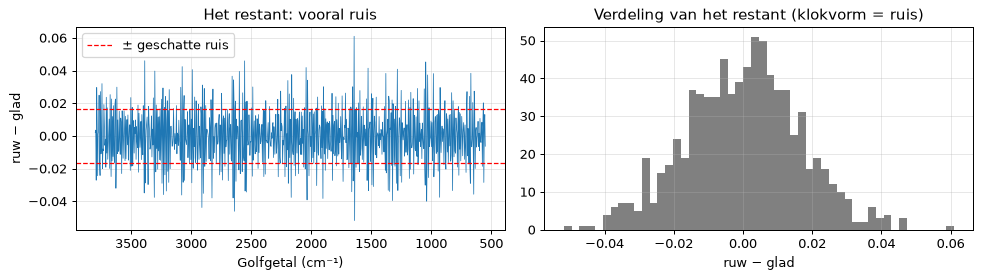

In [5]:
restant = ruw - glad
mad = np.median(np.abs(restant - np.median(restant)))
ruis_geschat = 1.4826 * mad                                   # dit is wat schat_ruis() in de app doet

fig, (links, rechts) = plt.subplots(1, 2, figsize=(11, 3.2))
links.plot(x, restant, lw=0.6)
links.axhline(+ruis_geschat, color="red", ls="--", lw=1); links.axhline(-ruis_geschat, color="red", ls="--", lw=1, label="± geschatte ruis")
links.set_ylabel("ruw − glad"); links.legend(); ir_as(links, "Het restant: vooral ruis")
rechts.hist(restant, bins=50, color="gray")
rechts.set_xlabel("ruw − glad"); rechts.set_title("Verdeling van het restant (klokvorm = ruis)")
plt.tight_layout(); plt.show()

print(f"Ruis die we er zelf in stopten      : {RUIS:.4f}")
print(f"Geschat met MAD (restant)           : {ruis_geschat:.4f}   <- de app gebruikt deze")
print(f"Zelfde uitkomst met de app-functie  : {schat_ruis(ruw):.4f}")
print(f"Gewone standaarddeviatie HEEL spectrum: {np.std(ruw):.4f}   <- veel te groot: de pieken tellen mee")
print()
if ruis_geschat < RUIS:
    print(f"Let op: de schatting is {100 * (1 - ruis_geschat / RUIS):.0f}% lager dan de echte ruis, omdat het filter een deel")
    print("van de ruis 'volgt' en dat deel niet in het restant belandt. Daarom gebruiken we straks een ruime factor (5x).")
else:
    print("De schatting ligt dicht bij (of boven) de echte ruis.")

### Stap 3 – Een drempel op de prominentie

**Prominentie** = hoe ver een piek boven zijn omgeving uitsteekt. Je meet vanaf de top naar beneden tot het hoogste
"dal" dat je moet oversteken om bij een hogere piek te komen. Dat is iets anders dan de *hoogte*: een klein bobbeltje
op de flank van een grote piek ligt hoog, maar steekt nauwelijks uit en heeft dus een kleine prominentie.

De regel van de app: een bult telt pas als piek als zijn prominentie groter is dan **beide** drempels:

- **5 × de geschatte ruis** (dan is het vrijwel zeker geen ruis), en
- **3% van de hoogste piek** (kleinere piekjes zijn voor het herkennen van groepen niet interessant).

Drempel uit de ruis      : 5 x 0.0166 = 0.0831
Drempel uit hoogste piek : 3% x 1.032 = 0.0309
Gebruikte drempel        : 0.0831 (de strengste van de twee)
Kleinste prominentie die door de drempel komt : 0.308
Grootste prominentie die wordt afgewezen      : 0.063
De zwakste echte piek steekt 4.9x zo ver uit als de sterkste ruisbult.


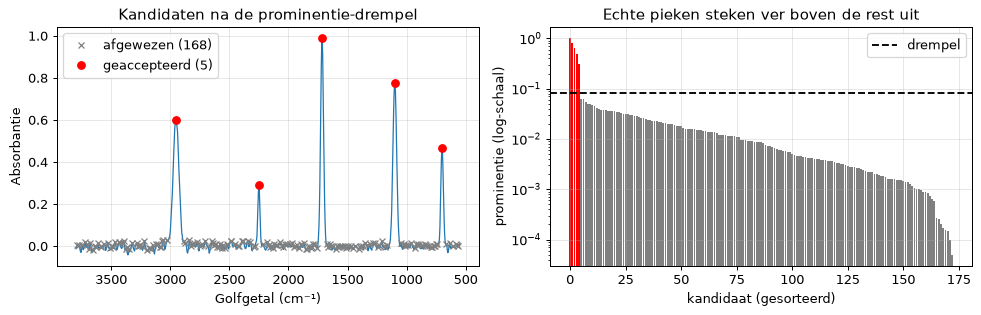

In [6]:
RUIS_FACTOR = 5.0
MIN_RELATIEF = 0.03

drempel_ruis = RUIS_FACTOR * ruis_geschat
drempel_relatief = MIN_RELATIEF * (glad.max() - glad.min())
drempel = max(drempel_ruis, drempel_relatief)
print(f"Drempel uit de ruis      : {RUIS_FACTOR:.0f} x {ruis_geschat:.4f} = {drempel_ruis:.4f}")
print(f"Drempel uit hoogste piek : {MIN_RELATIEF:.0%} x {glad.max() - glad.min():.3f} = {drempel_relatief:.4f}")
print(f"Gebruikte drempel        : {drempel:.4f} (de strengste van de twee)")

# Alle lokale maxima MET hun prominentie
kandidaten, eig = find_peaks(glad, prominence=0)
boven = eig["prominences"] >= drempel

fig, (links, rechts) = plt.subplots(1, 2, figsize=(11, 3.6))
links.plot(x, glad, lw=1)
links.plot(x[kandidaten[~boven]], glad[kandidaten[~boven]], "x", color="gray", ms=5, label=f"afgewezen ({(~boven).sum()})")
links.plot(x[kandidaten[boven]], glad[kandidaten[boven]], "ro", ms=6, label=f"geaccepteerd ({boven.sum()})")
links.set_ylabel("Absorbantie"); links.legend(); ir_as(links, "Kandidaten na de prominentie-drempel")

rechts.bar(np.arange(len(kandidaten)), np.sort(eig["prominences"])[::-1], color=["red" if p >= drempel else "gray" for p in np.sort(eig["prominences"])[::-1]])
rechts.axhline(drempel, color="black", ls="--", label="drempel")
rechts.set_yscale("log"); rechts.set_xlabel("kandidaat (gesorteerd)"); rechts.set_ylabel("prominentie (log-schaal)")
rechts.set_title("Echte pieken steken ver boven de rest uit"); rechts.legend()
plt.tight_layout(); plt.show()

kleinste_geaccepteerd = eig["prominences"][boven].min()
grootste_afgewezen = eig["prominences"][~boven].max()
print(f"Kleinste prominentie die door de drempel komt : {kleinste_geaccepteerd:.3f}")
print(f"Grootste prominentie die wordt afgewezen      : {grootste_afgewezen:.3f}")
print(f"De zwakste echte piek steekt {kleinste_geaccepteerd / grootste_afgewezen:.1f}x zo ver uit als de sterkste ruisbult.")

In de rechter grafiek en de getallen hierboven zie je de **kloof** tussen de echte pieken en de ruisbulten.
De drempel ligt in die kloof.

### Stap 4 – Minimale breedte (losse uitschieters eruit)

Soms geeft een storing één meetpunt dat ver omhoog schiet (een "spike"). Die kan een grote prominentie hebben, maar is
maar **1 punt breed**. Een echte absorptieband is altijd een paar punten breed. We meten de breedte op halve hoogte in
het **ruwe** spectrum (gladmaken smeert een spike uit, waardoor hij op een smalle piek gaat lijken) en eisen minimaal
1,5 rasterpunt (6 cm⁻¹).

Zonder breedte-eis: [698, 1098, 1714, 1998, 2250, 2954]
Met breedte-eis   : [698, 1098, 1714, 2250, 2954]


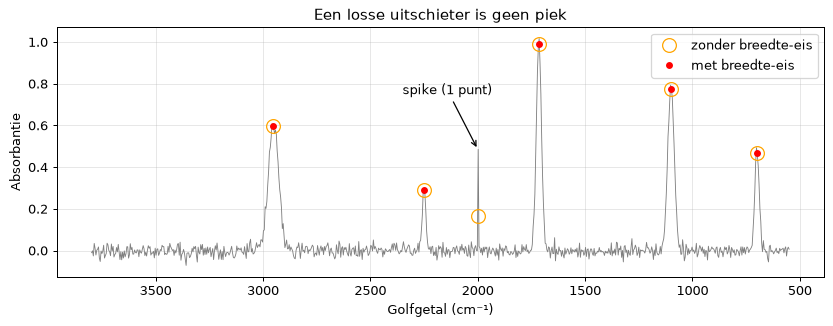

In [7]:
met_spike = ruw.copy()
plek = np.argmin(np.abs(x - 2000))
met_spike[plek] += 0.5                                         # een nep-storing van 1 punt bij 2000 cm⁻¹

zonder_breedte_eis = detecteer_pieken(x, met_spike, min_breedte_punten=0)
met_breedte_eis = detecteer_pieken(x, met_spike)               # standaard: minimaal 1,5 punt

fig, ax = plt.subplots()
ax.plot(x, met_spike, lw=0.7, color="gray")
ax.plot([p.golfgetal for p in zonder_breedte_eis], [p.hoogte for p in zonder_breedte_eis], "o", mfc="none", mec="orange", ms=11, label="zonder breedte-eis")
ax.plot([p.golfgetal for p in met_breedte_eis], [p.hoogte for p in met_breedte_eis], "r.", ms=9, label="met breedte-eis")
ax.annotate("spike (1 punt)", (2000, met_spike[plek]), xytext=(2350, 0.75), arrowprops=dict(arrowstyle="->"))
ax.set_ylabel("Absorbantie"); ax.legend(); ir_as(ax, "Een losse uitschieter is geen piek")
plt.show()
print("Zonder breedte-eis:", [round(p.golfgetal) for p in zonder_breedte_eis])
print("Met breedte-eis   :", [round(p.golfgetal) for p in met_breedte_eis])

### Controle: zijn precies de juiste pieken gevonden?

Nu de hele keten in één keer, met de functie die de app gebruikt (`detecteer_pieken`). We vergelijken de uitkomst met
de posities die we er zelf in gestopt hebben. Tolerantie: ± 8 cm⁻¹ (twee rasterpunten).

  bekend  gevonden  verschil  hoogte  breedte   oordeel
     700       698        -2    0.47       26   GOED
    1100      1098        -2    0.78       37   GOED
    1715      1714        -1    0.99       29   GOED
    2250      2250        +0    0.29       22   GOED
    2950      2954        +4    0.60       59   GOED

Aantal gevonden pieken: 5 (verwacht: 5)
✔ Alle vijf bekende pieken gevonden binnen ±8 cm⁻¹, en geen enkele nep-piek.


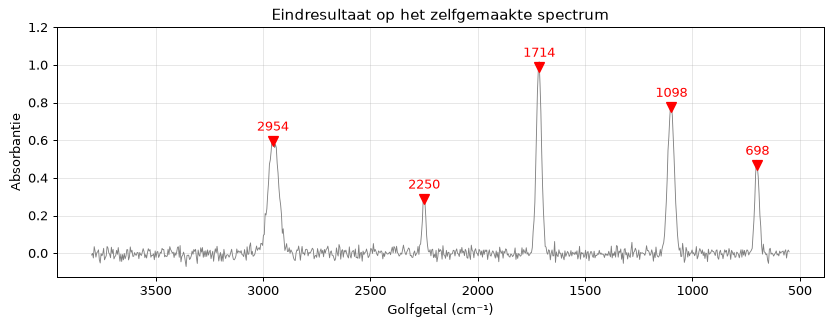

In [8]:
gevonden = detecteer_pieken(x, ruw)
TOLERANTIE = 8.0

print(f"{'bekend':>8} {'gevonden':>9} {'verschil':>9} {'hoogte':>7} {'breedte':>8}   oordeel")
alles_goed = True
for positie, hoogte, breedte in BEKENDE_PIEKEN:
    dichtstbij = min(gevonden, key=lambda p: abs(p.golfgetal - positie))
    verschil = dichtstbij.golfgetal - positie
    ok = abs(verschil) <= TOLERANTIE
    alles_goed &= ok
    print(f"{positie:8.0f} {dichtstbij.golfgetal:9.0f} {verschil:+9.0f} {dichtstbij.hoogte:7.2f} {dichtstbij.breedte:8.0f}   {'GOED' if ok else 'FOUT'}")

print(f"\nAantal gevonden pieken: {len(gevonden)} (verwacht: {len(BEKENDE_PIEKEN)})")
assert alles_goed, "niet alle bekende pieken zijn gevonden"
assert len(gevonden) == len(BEKENDE_PIEKEN), "er zijn nep-pieken gevonden"
print("✔ Alle vijf bekende pieken gevonden binnen ±8 cm⁻¹, en geen enkele nep-piek.")

fig, ax = plt.subplots()
ax.plot(x, ruw, lw=0.7, color="gray")
for p in gevonden:
    ax.plot(p.golfgetal, p.hoogte, "rv", ms=8)
    ax.annotate(f"{p.golfgetal:.0f}", (p.golfgetal, p.hoogte), xytext=(0, 8), textcoords="offset points", ha="center", color="red")
ax.set_ylim(top=1.2); ax.set_ylabel("Absorbantie"); ir_as(ax, "Eindresultaat op het zelfgemaakte spectrum")
plt.show()

---
## Deel B – Een echt spectrum: aceton

Nu hetzelfde op een echt spectrum uit de NIST-database. Aceton (propanon, CH₃–CO–CH₃) heeft een C=O-groep. Die geeft
een sterke piek rond **1715 cm⁻¹ in vloeistof** en iets hoger, rond **1730–1740 cm⁻¹, in gasfase**. Dit spectrum is in
gasfase gemeten.

Eerst lezen we het JCAMP-DX-bestand in en doen we de voorbewerking van de app (x naar cm⁻¹, y naar absorbantie, op het
raster van 4 cm⁻¹, basislijn op 0 en hoogste piek op 1).

Titel      : Acetone
CAS-nummer : 67-64-1
Formule    : C 3 H 6 O
Toestand   : gas
Eenheden   : 1/CM / ABSORBANCE
Meetpunten : 880 (450 - 3966 cm⁻¹)


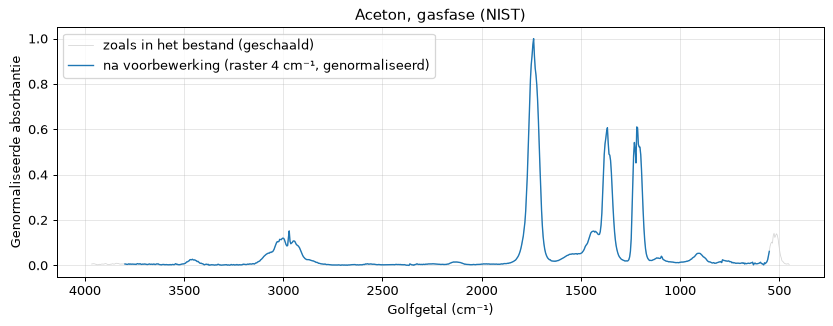

In [9]:
pad = PROJECTMAP / "research" / "voorbeeldspectra" / "aceton_gas_C67641_IR_0.jdx"
spectrum = lees_jcamp_bestand(pad)
print("Titel      :", spectrum.titel)
print("CAS-nummer :", spectrum.cas)
print("Formule    :", spectrum.formule)
print("Toestand   :", spectrum.toestand)
print("Eenheden   :", spectrum.x_eenheid, "/", spectrum.y_eenheid)
print("Meetpunten :", spectrum.x.size, f"({spectrum.x.min():.0f} - {spectrum.x.max():.0f} cm⁻¹)")

voorbewerkt = bewerk_voor(spectrum)
golfgetal = RASTER[voorbewerkt.masker]
absorbantie = voorbewerkt.absorbantie[voorbewerkt.masker]

fig, ax = plt.subplots()
ax.plot(spectrum.x, spectrum.y / spectrum.y.max(), lw=0.6, color="lightgray", label="zoals in het bestand (geschaald)")
ax.plot(golfgetal, absorbantie, lw=1.1, label="na voorbewerking (raster 4 cm⁻¹, genormaliseerd)")
ax.set_ylabel("Genormaliseerde absorbantie"); ax.legend(); ir_as(ax, "Aceton, gasfase (NIST)")
plt.show()

Geschatte ruis: 0.0006   drempel voor prominentie: 0.0291

 golfgetal  hoogte  prominentie  breedte
       906    0.05         0.04       62
      1210    0.57         0.55       52
      1370    0.59         0.57       50
      1742    0.97         0.97       58
      2970    0.12         0.12      141
      3002    0.12         0.03       39


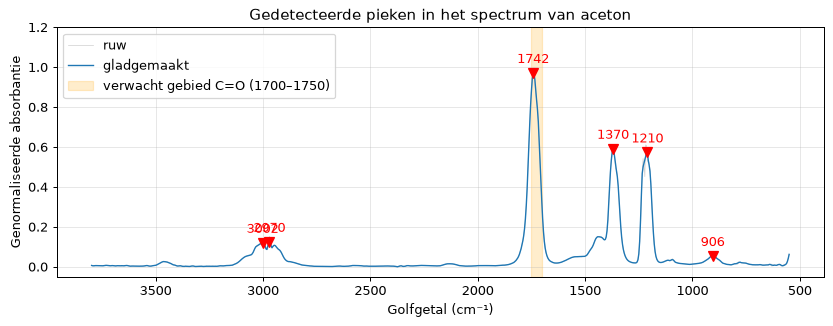

In [10]:
# De vier stappen, nu op het echte spectrum
glad = maak_glad(absorbantie)                                  # stap 1
ruis = schat_ruis(absorbantie, glad)                           # stap 2
drempel = max(5.0 * ruis, 0.03 * (glad.max() - glad.min()))    # stap 3
pieken = detecteer_pieken(golfgetal, absorbantie)              # stap 3 + 4 samen

print(f"Geschatte ruis: {ruis:.4f}   drempel voor prominentie: {drempel:.4f}")
print(f"\n{'golfgetal':>10} {'hoogte':>7} {'prominentie':>12} {'breedte':>8}")
for p in pieken:
    print(f"{p.golfgetal:10.0f} {p.hoogte:7.2f} {p.prominentie:12.2f} {p.breedte:8.0f}")

fig, ax = plt.subplots()
ax.plot(golfgetal, absorbantie, lw=0.6, color="lightgray", label="ruw")
ax.plot(golfgetal, glad, lw=1.1, label="gladgemaakt")
ax.axvspan(1700, 1750, color="orange", alpha=0.2, label="verwacht gebied C=O (1700–1750)")
for p in pieken:
    ax.plot(p.golfgetal, p.hoogte, "rv", ms=8)
    ax.annotate(f"{p.golfgetal:.0f}", (p.golfgetal, p.hoogte), xytext=(0, 8), textcoords="offset points", ha="center", color="red")
ax.set_ylim(top=1.2); ax.set_ylabel("Genormaliseerde absorbantie"); ax.legend(loc="upper left"); ir_as(ax, "Gedetecteerde pieken in het spectrum van aceton")
plt.show()

In [11]:
# Controle: ligt er een piek in het gebied waar de C=O van aceton hoort te liggen?
co_pieken = [p for p in pieken if 1700 <= p.golfgetal <= 1750]
assert len(co_pieken) == 1, "er hoort precies een piek tussen 1700 en 1750 cm⁻¹ te liggen"
co = co_pieken[0]
hoogste = max(pieken, key=lambda p: p.hoogte)
assert co is hoogste, "de C=O-piek hoort de sterkste piek van aceton te zijn"
print(f"✔ C=O-piek van aceton gevonden bij {co.golfgetal:.0f} cm⁻¹ (verwacht: 1700–1750 cm⁻¹).")
print(f"✔ Het is de sterkste piek van het spectrum (relatieve hoogte {co.hoogte:.2f}).")
print(f"  Aantal pieken in totaal: {len(pieken)} — geen wildgroei aan ruispiekjes.")

✔ C=O-piek van aceton gevonden bij 1742 cm⁻¹ (verwacht: 1700–1750 cm⁻¹).
✔ Het is de sterkste piek van het spectrum (relatieve hoogte 0.97).
  Aantal pieken in totaal: 6 — geen wildgroei aan ruispiekjes.


### Zelfde stof, ander bestand: micrometer en transmissie

In de database zit ook een ouder spectrum van aceton met de x-as in **micrometer** en de y-as in **transmissie**.
Na de voorbewerking (cm⁻¹ = 10 000 / µm en A = −log₁₀ T) moet dezelfde C=O-piek tevoorschijn komen.

Eenheden in dit bestand: MICROMETERS / TRANSMITTANCE | x loopt van 2.00 tot 15.00 µm
✔ C=O-piek in het omgerekende spectrum bij 1750 cm⁻¹ (ander bestand: 1742 cm⁻¹).


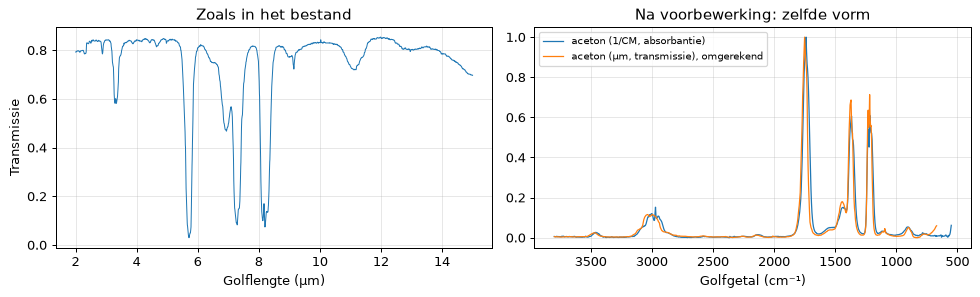

In [12]:
oud = lees_jcamp_bestand(PROJECTMAP / "research" / "voorbeeldspectra" / "aceton_gas_micrometer_C67641_IR_1.jdx")
print("Eenheden in dit bestand:", oud.x_eenheid, "/", oud.y_eenheid, f"| x loopt van {oud.x.min():.2f} tot {oud.x.max():.2f} µm")
voorbewerkt_oud = bewerk_voor(oud)
pieken_oud = detecteer_pieken(RASTER[voorbewerkt_oud.masker], voorbewerkt_oud.absorbantie[voorbewerkt_oud.masker])

fig, (links, rechts) = plt.subplots(1, 2, figsize=(11, 3.4))
links.plot(oud.x, oud.y, lw=0.8)
links.set_xlabel("Golflengte (µm)"); links.set_ylabel("Transmissie"); links.set_title("Zoals in het bestand")
rechts.plot(RASTER, voorbewerkt.absorbantie, lw=1, label="aceton (1/CM, absorbantie)")
rechts.plot(RASTER, np.where(voorbewerkt_oud.masker, voorbewerkt_oud.absorbantie, np.nan), lw=1, label="aceton (µm, transmissie), omgerekend")
rechts.legend(fontsize=8); ir_as(rechts, "Na voorbewerking: zelfde vorm")
plt.tight_layout(); plt.show()

co_oud = [p for p in pieken_oud if 1700 <= p.golfgetal <= 1760]
assert co_oud, "ook in het omgerekende spectrum hoort de C=O-piek gevonden te worden"
print(f"✔ C=O-piek in het omgerekende spectrum bij {co_oud[0].golfgetal:.0f} cm⁻¹ (ander bestand: {co.golfgetal:.0f} cm⁻¹).")

---
## Deel C – Matching: hoe vergelijk je twee spectra met één getal?

Na de voorbewerking is elk spectrum een **rij van 813 getallen**. Zo'n rij kun je zien als een pijl (vector) in een
ruimte met 813 dimensies. Drie manieren om twee pijlen te vergelijken (zie ook `docs/theorie_matching.md`):

| Methode | Vraag die je stelt | Formule |
|---|---|---|
| Euclidische afstand | Hoe ver liggen de pijlpunten uit elkaar? | $d = \sqrt{\sum (a_i - b_i)^2}$ |
| Cosinusgelijkenis | Wijzen de pijlen dezelfde kant op? | $\cos\theta = \dfrac{\sum a_i b_i}{\sqrt{\sum a_i^2}\,\sqrt{\sum b_i^2}}$ |
| Pearson-correlatie | Idem, maar na aftrekken van het gemiddelde | cosinus van $(a - \bar a)$ en $(b - \bar b)$ |

### Eerst met drie getallen, om na te rekenen

In [13]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([2.0, 2.0, 1.0])

euclidisch = np.sqrt(np.sum((a - b) ** 2))
cosinus = np.sum(a * b) / (np.sqrt(np.sum(a ** 2)) * np.sqrt(np.sum(b ** 2)))
pearson = np.corrcoef(a, b)[0, 1]

print("a =", a, "  b =", b)
print(f"Euclidische afstand = wortel((1-2)² + (2-2)² + (3-1)²) = wortel(5) = {euclidisch:.3f}")
print(f"Cosinusgelijkenis   = (1·2 + 2·2 + 3·1) / (wortel(14) · wortel(9)) = 9 / 11,225 = {cosinus:.3f}")
print(f"Pearson-correlatie  = {pearson:.3f}")
print()
print("Wat gebeurt er als spectrum b twee keer zo sterk is (bijv. een dikkere laag monster)?")
print(f"  cosinus(a, 2b)    = {np.sum(a * 2 * b) / (np.linalg.norm(a) * np.linalg.norm(2 * b)):.3f}   <- verandert NIET")
print(f"  euclidisch(a, 2b) = {np.linalg.norm(a - 2 * b):.3f}   <- verandert WEL")

a = [1. 2. 3.]   b = [2. 2. 1.]
Euclidische afstand = wortel((1-2)² + (2-2)² + (3-1)²) = wortel(5) = 2.236
Cosinusgelijkenis   = (1·2 + 2·2 + 3·1) / (wortel(14) · wortel(9)) = 9 / 11,225 = 0.802
Pearson-correlatie  = -0.866

Wat gebeurt er als spectrum b twee keer zo sterk is (bijv. een dikkere laag monster)?
  cosinus(a, 2b)    = 0.802   <- verandert NIET
  euclidisch(a, 2b) = 3.742   <- verandert WEL


### Nu met echte spectra

We vergelijken het acetonspectrum met (1) het andere acetonspectrum, (2) ethanol en (3) ethylacetaat, dat net als
aceton een C=O-groep heeft.

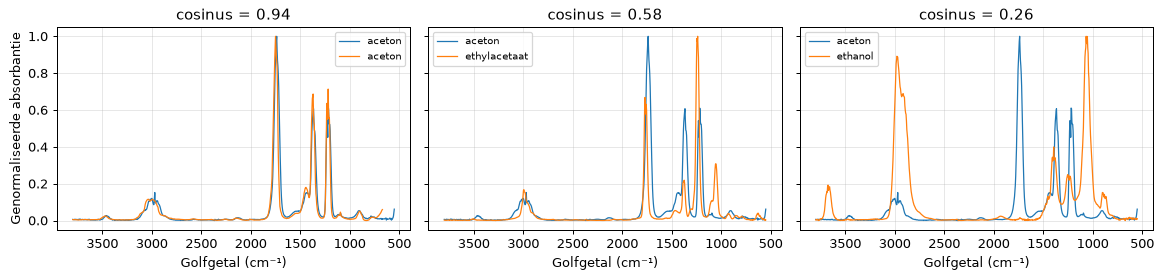

In [14]:
def laad(naam):
    v = bewerk_voor(lees_jcamp_bestand(PROJECTMAP / "research" / "voorbeeldspectra" / naam))
    return v.absorbantie, v.masker

def cosinus_op_overlap(a, ma, b, mb):
    # Cosinusgelijkenis over het deel dat BEIDE spectra gemeten hebben
    beide = ma & mb
    return float(a[beide] @ b[beide] / (np.linalg.norm(a[beide]) * np.linalg.norm(b[beide])))

aceton, m_aceton = laad("aceton_gas_C67641_IR_0.jdx")
anderen = {
    "aceton (ander bestand, µm/transmissie)": laad("aceton_gas_micrometer_C67641_IR_1.jdx"),
    "ethylacetaat (gas)": laad("ethylacetaat_gas_C141786_IR_0.jdx"),
    "ethanol (gas)": laad("ethanol_gas_C64175_IR_0.jdx"),
}

fig, assen = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (naam, (spec, m)) in zip(assen, anderen.items()):
    ax.plot(RASTER, aceton, lw=1, label="aceton")
    ax.plot(RASTER, np.where(m, spec, np.nan), lw=1, label=naam.split(" (")[0])
    ax.legend(fontsize=8); ir_as(ax, f"cosinus = {cosinus_op_overlap(aceton, m_aceton, spec, m):.2f}")
assen[0].set_ylabel("Genormaliseerde absorbantie")
plt.tight_layout(); plt.show()

### De "vergelijkingsvorm": logaritme + afgeleide

De kale absorbantie vergelijken werkt, maar heeft twee zwakke punten:

1. **De hoogste piek domineert.** Piekhoogtes hangen af van concentratie en fase; piek*posities* veel minder.
   Oplossing: de hoogtes **logaritmisch samendrukken**, zodat ook zwakke pieken meetellen.
2. **De basislijn telt mee.** Oplossing: de **eerste afgeleide** (de helling) vergelijken. Een langzaam verlopende
   basislijn heeft bijna geen helling en valt dus weg.

In de evaluatie verhoogde dit de top-1-nauwkeurigheid van ongeveer 31% naar ongeveer 53% (exacte cijfers:
`docs/evaluatie.md` en `docs/vergelijking_voorbewerking.md`). Hieronder zie je wat de omzetting met het spectrum doet.

Cosinusgelijkenis met aceton:          kale absorbantie    vergelijkingsvorm
  aceton (ander bestand, µm/transmissie)         0.94                0.88
  ethylacetaat (gas)                             0.58                0.37
  ethanol (gas)                                  0.26                0.17

Voorsprong van aceton op ethylacetaat (gas): kaal 0.36, vergelijkingsvorm 0.52 -> groter
Voorsprong van aceton op ethanol (gas): kaal 0.68, vergelijkingsvorm 0.71 -> groter


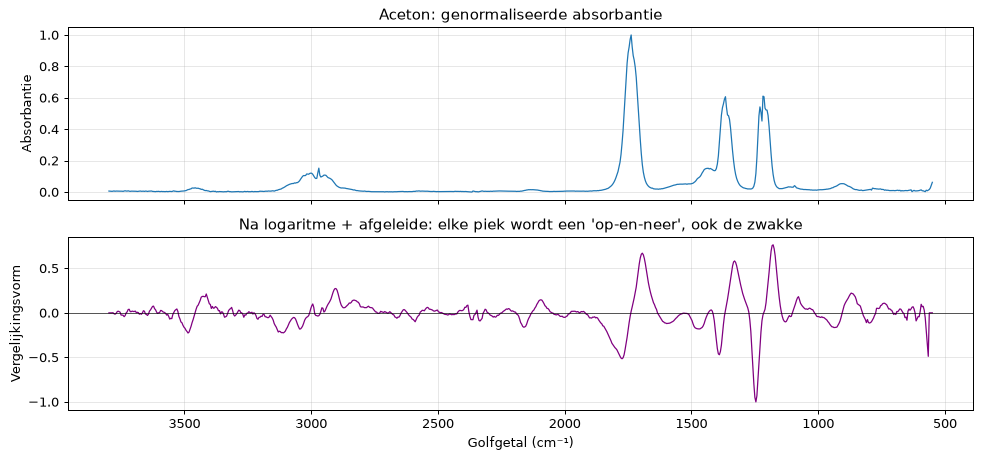

In [15]:
vorm = vergelijkingsvorm(aceton, m_aceton)

fig, (boven, onder) = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
boven.plot(RASTER, aceton, lw=1)
boven.set_ylabel("Absorbantie"); boven.set_title("Aceton: genormaliseerde absorbantie")
onder.plot(RASTER, vorm, lw=1, color="purple")
onder.axhline(0, color="black", lw=0.5)
onder.set_ylabel("Vergelijkingsvorm"); ir_as(onder, "Na logaritme + afgeleide: elke piek wordt een 'op-en-neer', ook de zwakke")
plt.tight_layout(); plt.show()

print("Cosinusgelijkenis met aceton:          kale absorbantie    vergelijkingsvorm")
uitkomst = {}
for naam, (spec, m) in anderen.items():
    kaal = cosinus_op_overlap(aceton, m_aceton, spec, m)
    v = vergelijkingsvorm(spec, m)
    met_vorm = cosinus_op_overlap(vorm, m_aceton, v, m)
    uitkomst[naam] = (kaal, met_vorm)
    print(f"  {naam:40s} {kaal:10.2f} {met_vorm:19.2f}")

juist_kaal, juist_vorm = uitkomst["aceton (ander bestand, µm/transmissie)"]
print()
for naam, (kaal, met_vorm) in uitkomst.items():
    if naam.startswith("aceton"):
        continue
    groter = (juist_vorm - met_vorm) > (juist_kaal - kaal)
    print(f"Voorsprong van aceton op {naam}: kaal {juist_kaal - kaal:.2f}, vergelijkingsvorm {juist_vorm - met_vorm:.2f}"
          f" -> {'groter' if groter else 'NIET groter'}")

### Zoeken in de hele bibliotheek

Tot slot de echte zoekactie van de app: het acetonspectrum vergelijken met alle spectra in de bibliotheek. Dit is
gevectoriseerd: geen lus over 18 000 spectra, maar een paar matrixvermenigvuldigingen. (Deze cel werkt alleen als de
database is gedownload met `setup.bat`.)

In [16]:
import time

if (PROJECTMAP / "data" / "library.npz").exists():
    from stofherkenner.matching import laad_bibliotheek, zoek
    bibliotheek = laad_bibliotheek(PROJECTMAP / "data")
    print(f"Bibliotheek: {len(bibliotheek)} spectra van {bibliotheek.metadata['nist_id'].nunique()} stoffen\n")

    start = time.perf_counter()
    # negeer_identiek=True: het spectrum zelf doet niet mee, zodat het een eerlijke test is
    top5 = zoek(bibliotheek, aceton, m_aceton, methode="cosinus", top_n=5, negeer_identiek=True)
    duur = (time.perf_counter() - start) * 1000
    print(top5[["rang", "naam", "cas", "formule", "fase", "score"]].round({"score": 1}).to_string(index=False))
    print(f"\nZoektijd: {duur:.0f} ms")
else:
    print("De bibliotheek is nog niet gebouwd; draai eerst setup.bat.")

Bibliotheek: 18016 spectra van 15817 stoffen

 rang             naam       cas       formule fase  score
    1          Acetone   67-64-1 C H3 C O C H3  gas   95.8
    2 t-Butyl peroxide  110-05-4  C 8 H 18 O 2  gas   79.5
    3      FORMIC ACID   64-18-6       C H2 O2  gas   61.5
    4   Methoxyacetone 5878-19-3   C 4 H 8 O 2  gas   60.1
    5       2-Butanone   78-93-3     C 4 H 8 O  gas   55.8

Zoektijd: 27 ms


---
## Samenvatting

**Piekdetectie in vier stappen**

1. **Gladmaken** met een Savitzky-Golay-filter (boogjes door 7 punten): minder ruis, piekvorm blijft behouden.
2. **Ruis schatten** met de MAD van (ruw − glad): robuust, pieken tellen niet mee.
3. **Drempel op de prominentie**: minimaal 5× de ruis én minimaal 3% van de hoogste piek.
4. **Minimale breedte** in het ruwe spectrum: losse uitschieters vallen af.

Op het zelfgemaakte spectrum zijn precies de vijf bekende pieken gevonden (binnen ± 8 cm⁻¹) en geen enkele nep-piek.
Op het echte acetonspectrum is de C=O-piek gevonden in het verwachte gebied van 1700–1750 cm⁻¹.

**Matching**

- Een spectrum is een vector; gelijkenis meet je met cosinus, Pearson of Euclidische afstand.
- De app vergelijkt de *vergelijkingsvorm* (logaritme + afgeleide) met **cosinusgelijkenis**, omdat dat in de
  evaluatie het best werkte (`docs/evaluatie.md`).

Dezelfde controles draaien automatisch in `tests/test_piekdetectie.py` en `tests/test_matching.py`.